<div style="font-family: 'Times New Roman', serif;">

1. Let an ito process $S_t$ be an asset price. 

    $$dS_t = \mu(t,S_t)dt + \sigma(t, S_t)dW_t \tag{1}$$

<br><br>

2. Assume the asset price satisfies Geometric Brownian Motion  
: GBM is an ito process where $\mu(t, S_t) = rS_t$ and $\sigma(t, S_t) = \sigma S_t$

    $$dS_t = rS_tdt + \sigma S_t dW_t \tag{2}$$

    *Then,*
    $$(dS_t)^2 = (rS_tdt + \sigma S_t dW_t)^2 = r^2S_t^2(dt)^2 + 2r\sigma S_t^2 dtdW_t + \sigma^2 S_t^2 dW_t^2$$
    *by Ito's product rule $(dt)^2 = 0, dtdW_t = 0, (d{W_t})^2 = dt$*
    $$\therefore (dS_t)^2 = \sigma^2 S_t^2 dt \tag{3}$$

    **Caution : $dS_t \ne \sqrt{(dS_t)^2}$**  
    $(dS_t)^2$ denotes the infinitesimal quadratic variation, NOT algebraic squaring.
<br><br>

3. By ito's lemma, the differential of $f(S_t)$ is given as:

    $$df = \frac{\partial f}{\partial t}dt + \frac{\partial f}{\partial S}dS_t + \frac{1}{2}\frac{\partial^2 f}{\partial S^2}(dS_t)^2 \tag{4}$$
<br><br>
  
4. Define $f(S_t) = \ln(S_t/S_0)$, which is the *log-return* of the asset. 

    *partial derivative of f* : 
    $$\frac{\partial f}{\partial t} = 0 , \frac{\partial f}{\partial S} = \frac{1}{S_t}, \frac{\partial^2 f}{\partial S^2}= -\frac{1}{S_t^2} $$
<br><br>
  
5. Ito's lemma for the log-return of the asset

    $$df(S,t) = 0 + 
    (\frac{1}{S_t}) \underbrace{(rS_tdt + \sigma S_t dW_t)}_{\text{(2)}} +
    \frac{1}{2}(-\frac{1}{S_t^2})\underbrace{(\sigma^2S_t^2dt)}_{\text{(3)}} $$

    $$df(S,t) = (r -\frac{\sigma^2}{2})dt + \sigma dW_t $$
<br><br>


6. Discretization : Replacing infinitesimal increments $d$ with discrete increments $\Delta$


    Let ${\Tau} = {t}_{i=0,...n}$ denote a discrete time grid of the time interval $[0,T]$. 

    Define discrete-time process $X = (X_t)_{t\in\Tau}$ as
    $$\begin{cases}  
    X_{t_0} & \text{for } i = 0 \\
    X_{t_{i+1}} - X_{t_i} = (r-\frac{\sigma^2}{2} )\Delta{t_i}+ \sigma\sqrt{\Delta{t_i}}\mathcal{N}_i & \text{for } i = 0, ..., n-1
    \end{cases}$$

    Where $(\mathcal{N}_i)_{i=0}^{n-1} \overset{\text{i.i.d.}}{\sim} \mathcal{N}(0,1)$

</div>

<div style="font-family: 'Times New Roman', serif;">

##### Simulating paths of log-returns.

T : total time period  
r : drift  
sigma : volatility  
n : number of time steps  
m : number of simulations

</div>

In [1]:
import numpy as np

def simulate_gbm(T, r, sigma, n, m):

    tt = np.linspace(0., T, n+1)
    dt = T / n # time step size

    # size = (m,n) -> creates m*n array , m : row(path), n : column(time)
    # pre-define an numpy arrary of standard normal random variables (possible since N_i are i.i.d.)
    N = np.random.normal(0, 1, size = (m,n))

    dX = (r - sigma**2/2.)*dt + sigma*np.sqrt(dt)*N  # increments of the log return

    X = np.zeros((m, n+1))
    X[:, 1:] = np.cumsum(dX, axis=1) # cumulate along axis = 1 (time axis)

    return tt, X


<div style="font-family: 'Times New Roman', serif;">

##### Converting log-returns to asset price

$$X_t = \ln(\frac{S_t}{S_0})$$
$$S_t = S_0\exp{X_t}$$

S_0 : Starting asset price
</div>

In [2]:
def asset_price(S_0, X):
    
    return S_0 * np.exp(X)

In [3]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

def maturity_hist_on_ax(ax, S_T, current_m, current_n, S_0):

    ax.clear()

    true_mean = S_0 * np.exp(r * T)
    sample_mean = np.mean(S_T) 
    
    ax.hist(
        S_T, 
        bins=40, 
        density=True,
        alpha=0.6, color="#1f77b4", edgecolor="black", lw=0.5,
    )

    ax.axvline(
        sample_mean, 
        color="red", linestyle="dashed",
        label=f"Sample Mean: {sample_mean:.2f}",
    )
    ax.axvline(
        true_mean, 
        color="blue", linestyle=":",
        label=f"Theoretical Mean: {true_mean:.2f}",
    )

    ax.set_xlim(S_0 * 0.4, S_0 * 2.2) # fix axis
    #ax.set_ylim(0, 0.0025)
    ax.set_title(f"Distribution at Maturity T (m = {current_m:,}, n = {current_n})")
    ax.set_xlabel("Asset Price at Maturity (S_T)")
    ax.set_ylabel("Density")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")


<div style="font-family: 'Times New Roman', serif;">

#### Convergence of Sample Mean as $m \to \infty$

$(S_T^{(j)})_{j = 1,..,m}$ : $m$ independent and i.i.d. realizations of the terminal asset price.  

$$ \bar{S}_T^{(m)} = \frac{1}{m}\sum_{j=1}^m S_T^{(j)}$$

As the number of simulated paths $m$ increases, 
1. The sample mean $\bar{S}_T^{(m)}$ converges a.s. to the theoretical mean $\mathbb{E}[S_T]$
    </br></br>
    *[Almost Sure Convergence (Strong Law of Large Numbers)]*
    </br>
    *When $X_k$ is i.i.d., $\bar{X}_n\xrightarrow{\text{a.s.}}\mu \iff \mathbb{E}[|X_1|] < \infty$*
    
    Since $S_T^{(j)}$ are i.i.d. and
    $$\mathbb{E}[|S_T|] = \mathbb{E}[S_T] = S_0e^{rT} < \infty $$

    by the SLLN,
    $$\mathbb{P}(\lim_{m\to\infty}\bar{S}_T^{(m)} = \mathbb{E}[S_T]) = 1$$

</br></br>

2. Sampling error decreases at the rate $\mathcal{O}(m^{-1/2})$  

    $$X_T = (r-\frac{\sigma^2}{2})T+ \sigma\sqrt{\frac{T}{n}}\underbrace{\left(\sum_{i=0}^{n-1}Z_i\right)}_{\sim \mathbb{N}(0,n)} \stackrel{d}{=} (r-\frac{\sigma^2}{2})T+ \sigma\sqrt{T}Z$$

    **[!NOTE]**  
    In the gbm model, the number of time step $n$ has no effect on the distribution of log-returns at maturity

    </br>

    $$\mathbb{E}[S_T^2] 
    = S_0^2\mathbb{E}[e^{2((r-\frac{\sigma^2}{2})T+ \sigma\sqrt{T}\cdot Z)}] 
    = S_0^2e^{(2r-\sigma^2)T}\underbrace{\mathbb{E}[e^{2\sigma\sqrt{T}\cdot Z}]}_{\text{by the MGF } \mathbb{E}[e^{aZ}] = e^{\frac{a^2}{2}}} 
    = S_0^2e^{(2r-\sigma^2)T}e^{2\sigma^2T} 
    = S_0^2e^{(2r+\sigma^2)T} < \infty$$  
    </br>

    Since $S_T^{(j)}$ are i.i.d. and have finite variance, by the Central Limit Theorem:

    $$\sqrt{m}(\bar{S}_T^{(m)} - \mathbb{E}[S_T]) \xrightarrow{d} \mathcal{N}(0, \sigma_S^2) \quad \text{as }m\to\infty$$

    Therefore the standard deviation of $\bar{S}_T^{(m)}$ is calculated as :
    $$\sigma_S^2 = \text{Var}[\sqrt{m}(\bar{S}_T^{(m)} - \mathbb{E}[S_T])] = m\text{Var}(\bar{S}_T^{(m)})$$
    $$\text{SE}[\bar{S}_T^{(m)}] = \sqrt{\text{Var}(\bar{S}_T^{(m)})} = \frac{\sigma_S}{\sqrt{m}} \propto \frac{1}{\sqrt{m}} = \mathcal{O}\left(\frac{1}{\sqrt{m}}\right)$$

    **[!NOTE]**  
    While $\bar{S}_T^{(m)}$ is guaranteed to converge almost surely to $S_0e^rT$, the convergence rate of $\mathcal{O}(m^{-1/2})$ shows the computational limitation of standard monte carlo.
</br></br> 

</div>

In [4]:
T, r, sigma, S_0 = 1, 0.05, 0.2, 100

n = 100
m_list = np.unique(np.geomspace(10, 5000, 30).astype(int))
#m_list = np.linspace(10, 1000, 30).astype(int)
# np.linspace : generates evenly spaced values over a interval
# np.geomspace : generates evenly spaced values on a log scale (geometric progression)

fig_m, ax_m = plt.subplots(figsize = (8, 4.5))

def update_m(frame):
    current_m = m_list[frame]

    _, X = simulate_gbm(T, r, sigma, n, current_m)
    S_T = asset_price(S_0, X)[:, -1]

    maturity_hist_on_ax(ax_m, S_T, current_m, n, S_0)

ani_m = animation.FuncAnimation(fig_m, update_m, frames=len(m_list), interval = 500)
plt.close(fig_m)
HTML(ani_m.to_jshtml())

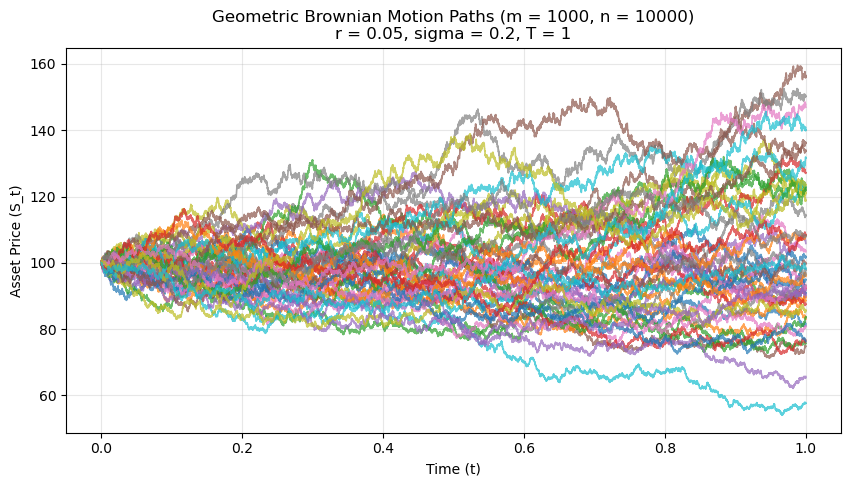

In [5]:

def plot_gbm_paths(tt, S, m, n, r, sigma, T):

    plt.figure(figsize=(10,5)) # setting a figure size
    plt.plot(tt, S[:50,:].T, lw= 1.2, alpha = 0.7) # lw : linewidth, alpha : transparency 

    plt.title(f"Geometric Brownian Motion Paths (m = {m}, n = {n})\n"
            f"r = {r}, sigma = {sigma}, T = {T}")
    plt.xlabel("Time (t)")
    plt.ylabel("Asset Price (S_t)")
    plt.grid(True, alpha=0.3)
    plt.show()

T, r, sigma, S_0 = 1, 0.05, 0.2, 100

n, m = 10000, 1000

# simulating m log returns 
tt, X = simulate_gbm(T, r, sigma, n, m)
# converting log returns to asset prices
S = asset_price(S_0, X)

# plotting the simulated GBM paths
plot_gbm_paths(tt, S[:50,:], m, n, r, sigma, T)